In [23]:
import numpy as np
import random as random
import matplotlib.pyplot as plt

## Código utilizado de ejercicios anteriores

In [24]:
# Definimos el fantoma
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

# Vectorizamos el fantoma por filas
x_fantoma = X_fantoma.reshape(-1)


def mascara_rayo(n, direccion, s):
    # Creamos una matriz de n por n llena de ceros
    matriz = np.array([[0] * n for _ in range(n)])

    # Recorremos todos los píxeles
    for i in range(n):
        for j in range(n):
            # Verificamos si el píxel pertenece al rayo
            if direccion[0] * i + direccion[1] * j == s:
                matriz[i, j] = 1

    return matriz


def matriz_proyeccion(n, direcciones):
    # Guardamos las máscaras vectorizadas
    matriz = []

    # Guardamos la dirección y el desplazamiento de cada rayo
    rayo = []

    for direccion in direcciones:
        valores_s = []

        # Calculamos todos los valores posibles de s
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)

        # Eliminamos los valores repetidos y los ordenamos
        valores_s = sorted(set(valores_s))

        # Construimos una máscara para cada valor de s
        for s in valores_s:
            rayo.append((tuple(direccion), s))
            mascara = mascara_rayo(n, direccion, s)
            matriz.append(mascara.reshape(-1))

    return np.array(matriz), rayo


# Definimos las siete direcciones utilizadas por A7
D7 = [(1, 0), (0, 1), (1, 1), (1, -1), (2, 1), (1, 2), (3, 1)]

# Construimos la matriz de proyección A7
A7, rayos_A7 = matriz_proyeccion(8, D7)

# Calculamos las mediciones ideales
b7 = A7 @ x_fantoma

# Fijamos la semilla para obtener el mismo ruido del ejercicio anterior
np.random.seed(18)

# Generamos un vector aleatorio del mismo tamaño que b7
z = np.random.normal(0, 1, len(b7))

# Calculamos el tamaño típico de las mediciones
escala = np.sqrt(np.mean(b7**2))

# Construimos las mediciones con sigma = 0.06
sigma = 0.06
n_sigma = sigma * escala * z
b_sigma = b7 + n_sigma

# Verificamos las dimensiones necesarias
print("Dimensiones de A7:", A7.shape)
print("Dimensiones de b_sigma:", b_sigma.shape)

Dimensiones de A7: (119, 64)
Dimensiones de b_sigma: (119,)


## a) Función de costo, gradiente y Hessiana

Definimos la función de costo como $E(x)=\frac{1}{2}\|A_7x-b_\sigma\|^2$. Esta función mide la diferencia total entre las mediciones producidas por una imagen $x$ y las mediciones ruidosas $b_\sigma$. Cuanto menor es el costo, mejor reproduce la imagen las mediciones.

El gradiente está dado por $\nabla E(x)=A_7^T(A_7x-b_\sigma)$ y señala la dirección de mayor crecimiento del costo. Por lo tanto, para reducir el costo debemos avanzar en la dirección contraria al gradiente.

La Hessiana es $H=A_7^TA_7$ y representa la curvatura de la función. Como la función de costo es cuadrática, la Hessiana es constante y no depende de $x$.

In [25]:
# Definimos la función de costo
def costo(x):
    residuo = A7 @ x - b_sigma
    return 0.5 * np.linalg.norm(residuo)**2


# Definimos la función que calcula el gradiente
def gradiente(x):
    residuo = A7 @ x - b_sigma
    return A7.T @ residuo


# Construimos la Hessiana
H = A7.T @ A7

# Verificamos sus dimensiones y su simetría
print("Dimensiones de H:", H.shape)
print("¿H es simétrica?", np.allclose(H, H.T))
print("Norma de H - H.T:", np.linalg.norm(H - H.T))

Dimensiones de H: (64, 64)
¿H es simétrica? True
Norma de H - H.T: 0.0


Obtuvimos una Hessiana de dimensiones $64\times64$, ya que la función de costo depende de los 64 valores de los píxeles. La comparación entre $H$ y $H^T$ devolvió `True` y la norma de su diferencia fue igual a cero. Por lo tanto, verificamos numéricamente que la Hessiana es simétrica.

## b) Implementación de gradiente descendiente

Implementamos gradiente descendiente mediante la actualización $x_{t+1}=x_t-\alfa\nabla E(x_t)$, comenzando con $x_0=0$. En cada iteración registramos el costo y la norma del gradiente para observar si el método se aproxima al mínimo.

La tasa de aprendizaje $\alfa$ determina el tamaño de cada paso. Para esta primera ejecución utilizamos $\alfa=0.02$.

In [26]:
def gradiente_descendiente(alfa, cantidad_iteraciones):

    # Comenzamos con una imagen de 64 píxeles iguales a cero
    x = np.zeros(64)

    # Creamos listas para guardar la evolución del método
    costos = []
    normas_gradiente = []

    for _ in range(cantidad_iteraciones):

        # Calculamos el costo y el gradiente en la posición actual
        costo_actual = costo(x)
        gradiente_actual = gradiente(x)

        # Guardamos los resultados de la iteración
        costos.append(costo_actual)
        normas_gradiente.append(np.linalg.norm(gradiente_actual))

        # Actualizamos la imagen avanzando en dirección contraria al gradiente
        x = x - alfa * gradiente_actual

    return x, costos, normas_gradiente



# Elegimos la tasa de aprendizaje y la cantidad de iteraciones
alfa = 0.02
cantidad_iteraciones = 1000

# Ejecutamos gradiente descendiente
x_gradiente, costos, normas_gradiente = gradiente_descendiente(alfa, cantidad_iteraciones)

print("Costo inicial:", costos[0])
print("Costo final:", costos[-1])
print("Norma inicial del gradiente:", normas_gradiente[0])
print("Norma final del gradiente:", normas_gradiente[-1])

Costo inicial: 73.02757069445676
Costo final: 0.14808926017485552
Norma inicial del gradiente: 67.52145760080006
Norma final del gradiente: 6.296309243452008e-07


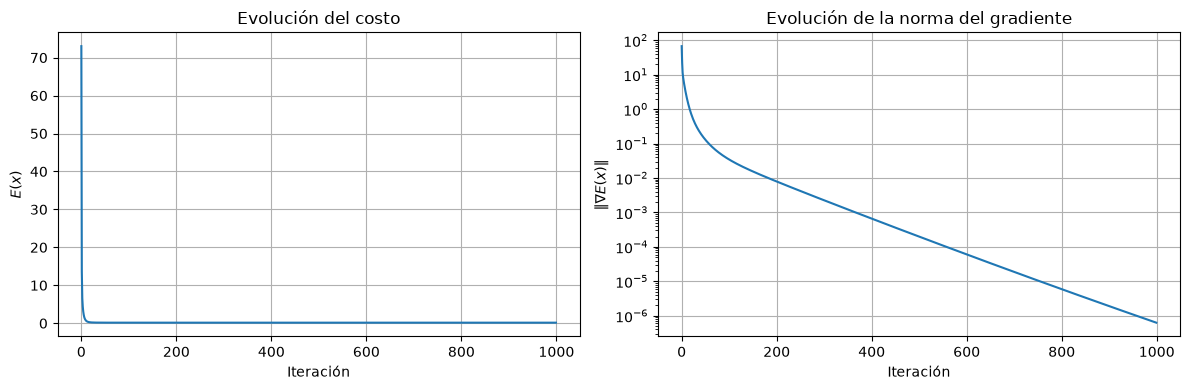

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(costos)
axes[0].set_title("Evolución del costo")
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("$E(x)$")
axes[0].grid()

axes[1].plot(normas_gradiente)
axes[1].set_title("Evolución de la norma del gradiente")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel("$\\|\\nabla E(x)\\|$")
axes[1].set_yscale("log")
axes[1].grid()

plt.tight_layout()
plt.show()

El costo disminuyó desde aproximadamente $73.03$ hasta $0.1481$, mientras que la norma del gradiente se redujo desde $67.52$ hasta aproximadamente $6.30\times10^{-7}$. Estos resultados indican que el método se aproximó a un punto en el que el costo es mínimo y el gradiente es prácticamente nulo.

El costo final no es igual a cero porque las mediciones $b_\sigma$ contienen ruido y no existe, en general, una imagen capaz de reproducirlas exactamente. Por lo tanto, gradiente descendiente encuentra la imagen que produce la mejor aproximación posible según el criterio de mínimos cuadrados.

## c) Efecto de la tasa de aprendizaje

Calculamos el mayor autovalor $\mu_{\max}$ de la Hessiana para determinar el intervalo de tasas de aprendizaje estables. Para que gradiente descendiente converja, la tasa debe cumplir $0<\alfa<2/\mu_{\max}$.

Luego probamos distintas tasas dentro y fuera de este intervalo y comparamos la evolución del costo.

In [28]:
# Calculamos los autovalores de H
autovalores = np.linalg.eigvalsh(H)

# Seleccionamos el mayor autovalor
mu_max = autovalores.max()

# Calculamos el límite superior para alfa
limite_alfa = 2 / mu_max

print("Mayor autovalor:", mu_max)
print("Límite superior para alfa:", limite_alfa)
print("¿alfa = 0.02 está dentro del intervalo?", 0 < 0.02 < limite_alfa)

Mayor autovalor: 36.463405008015556
Límite superior para alfa: 0.05484951280771367
¿alfa = 0.02 está dentro del intervalo? True


In [29]:
# Elegimos tres tasas dentro del intervalo estable
alfa_1 = 0.5 / mu_max
alfa_2 = 1.0 / mu_max
alfa_3 = 1.8 / mu_max

# Elegimos una tasa ligeramente superior al límite
alfa_fuera = 2.05 / mu_max

print("alfa 1:", alfa_1)
print("alfa 2:", alfa_2)
print("alfa 3:", alfa_3)
print("alfa fuera del intervalo:", alfa_fuera)

alfa 1: 0.013712378201928417
alfa 2: 0.027424756403856835
alfa 3: 0.049364561526942304
alfa fuera del intervalo: 0.056220750627906504


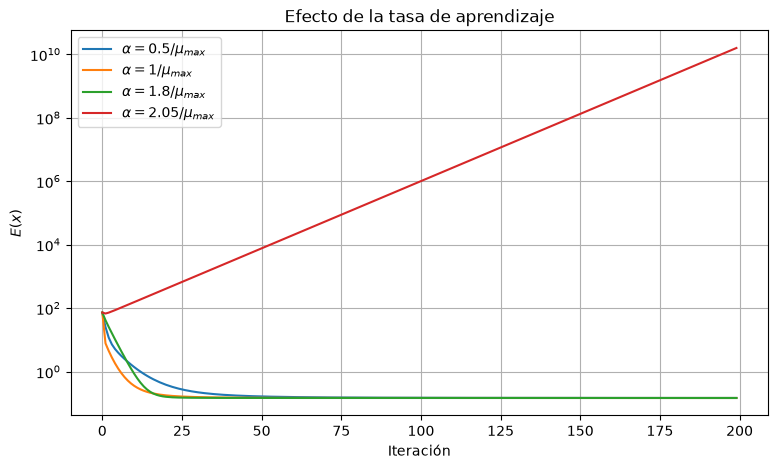

Costo final con alfa 1: 0.14835302008262483
Costo final con alfa 2: 0.1480972342722867
Costo final con alfa 3: 0.14808929714226138
Costo final con alfa fuera del intervalo: 15910437180.131699


In [30]:
# Ejecutamos el método con las cuatro tasas
x_1, costos_1, normas_1 = gradiente_descendiente(alfa_1, 200)
x_2, costos_2, normas_2 = gradiente_descendiente(alfa_2, 200)
x_3, costos_3, normas_3 = gradiente_descendiente(alfa_3, 200)
x_fuera, costos_fuera, normas_fuera = gradiente_descendiente(alfa_fuera, 200)

plt.figure(figsize=(9, 5))

plt.plot(costos_1, label="$\\alpha=0.5/\\mu_{max}$")
plt.plot(costos_2, label="$\\alpha=1/\\mu_{max}$")
plt.plot(costos_3, label="$\\alpha=1.8/\\mu_{max}$")
plt.plot(costos_fuera, label="$\\alpha=2.05/\\mu_{max}$")

plt.xlabel("Iteración")
plt.ylabel("$E(x)$")
plt.title("Efecto de la tasa de aprendizaje")
plt.yscale("log")
plt.grid()
plt.legend()
plt.show()

print("Costo final con alfa 1:", costos_1[-1])
print("Costo final con alfa 2:", costos_2[-1])
print("Costo final con alfa 3:", costos_3[-1])
print("Costo final con alfa fuera del intervalo:", costos_fuera[-1])

Obtuvimos $\mu_{\max}\approx36.46$, por lo que las tasas estables deben cumplir $0<\alpha<0.05485$. La tasa $\alpha=0.02$ utilizada anteriormente pertenece a este intervalo.

Las tres tasas estables redujeron el costo hasta un valor cercano a $0.1481$. Entre ellas, $\alpha=1.8/\mu_{\max}$ se aproximó más rápidamente al mínimo porque realizó pasos más grandes.

En cambio, con $\alpha=2.05/\mu_{\max}$, que supera el límite, el costo creció hasta aproximadamente $1.59\times10^{10}$. Por lo tanto, verificamos que una tasa dentro del intervalo permite la convergencia, mientras que una tasa demasiado grande vuelve inestable el método.

## d) Método de Newton

Implementamos el método de Newton resolviendo el sistema $Hp_t=\nabla E(x_t)$ y actualizando la reconstrucción mediante $x_{t+1}=x_t-p_t$.  Comenzamos con $x_0=0$ y realizamos una única iteración para verificar si el método alcanza directamente la solución.

In [31]:
# Comenzamos con una imagen de 64 píxeles iguales a cero
x_newton = np.zeros(64)

# Calculamos el costo inicial
costo_inicial_newton = costo(x_newton)

# Calculamos el gradiente inicial
gradiente_newton = gradiente(x_newton)

# Resolvemos el sistema H p = gradiente
p = np.linalg.solve(H, gradiente_newton)

# Actualizamos la reconstrucción
x_newton = x_newton - p

# Calculamos el costo y la norma del gradiente después de una iteración
costo_final_newton = costo(x_newton)
norma_gradiente_newton = np.linalg.norm(gradiente(x_newton))

print("Costo inicial:", costo_inicial_newton)
print("Costo después de una iteración:", costo_final_newton)
print("Norma del gradiente después de una iteración:", norma_gradiente_newton)

Costo inicial: 73.02757069445676
Costo después de una iteración: 0.14808926017449256
Norma del gradiente después de una iteración: 1.5725894826169177e-14


El costo disminuyó desde aproximadamente $73.03$ hasta $0.1481$ en una sola iteración. Además, la norma del gradiente quedó en $1.57\times10^{-14}\approx0$, por lo que verificamos que Newton alcanzó numéricamente el mínimo. Esto ocurre porque la función de costo es cuadrática y su Hessiana $H=A_7^TA_7$ es constante.

## e) Comparación de las reconstrucciones

Comparamos las reconstrucciones obtenidas mediante gradiente descendiente, Newton y `np.linalg.lstsq`. Para cada método calculamos el costo final, el error relativo respecto del fantoma y la distancia con respecto a la solución obtenida con `lstsq`.

In [32]:
# Calculamos la solución directa de mínimos cuadrados
x_lstsq = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]

# Calculamos los errores relativos respecto del fantoma
error_gradiente = np.linalg.norm(x_gradiente - x_fantoma) / np.linalg.norm(x_fantoma)
error_newton = np.linalg.norm(x_newton - x_fantoma) / np.linalg.norm(x_fantoma)
error_lstsq = np.linalg.norm(x_lstsq - x_fantoma) / np.linalg.norm(x_fantoma)

# Calculamos las distancias con respecto a la solución de lstsq
diferencia_gradiente = np.linalg.norm(x_gradiente - x_lstsq)
diferencia_newton = np.linalg.norm(x_newton - x_lstsq)
diferencia_lstsq = np.linalg.norm(x_lstsq - x_lstsq)

print(f"{'Método':<22} {'Costo':<14} {'Error relativo':<18} {'Distancia a lstsq':<20}")
print("-" * 74)

print(f"{'Gradiente descendiente':<22} {costo(x_gradiente):<14.6f} {error_gradiente:<18.6f} {diferencia_gradiente:<20.2e}")
print(f"{'Newton':<22} {costo(x_newton):<14.6f} {error_newton:<18.6f} {diferencia_newton:<20.2e}")
print(f"{'lstsq':<22} {costo(x_lstsq):<14.6f} {error_lstsq:<18.6f} {diferencia_lstsq:<20.2e}")

Método                 Costo          Error relativo     Distancia a lstsq   
--------------------------------------------------------------------------
Gradiente descendiente 0.148089       0.147192           1.14e-06            
Newton                 0.148089       0.147193           8.09e-15            
lstsq                  0.148089       0.147193           0.00e+00            


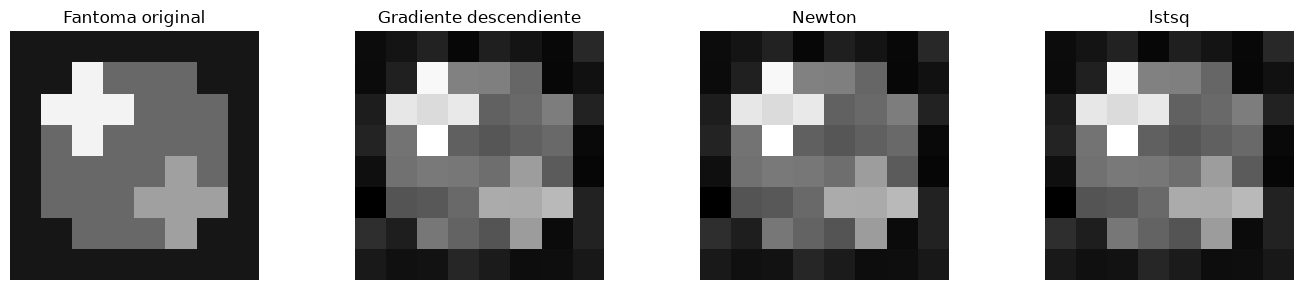

In [33]:
# Calculamos una escala común para todas las imágenes
vmin_imagenes = min(x_fantoma.min(), x_gradiente.min(), x_newton.min(), x_lstsq.min())
vmax_imagenes = max(x_fantoma.max(), x_gradiente.max(), x_newton.max(), x_lstsq.max())

# Creamos la grilla
fig, axes = plt.subplots(1, 4, figsize=(14, 3))

axes[0].imshow(x_fantoma.reshape(8, 8), cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[0].set_title("Fantoma original")
axes[0].axis("off")

axes[1].imshow(x_gradiente.reshape(8, 8), cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[1].set_title("Gradiente descendiente")
axes[1].axis("off")

axes[2].imshow(x_newton.reshape(8, 8), cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[2].set_title("Newton")
axes[2].axis("off")

axes[3].imshow(x_lstsq.reshape(8, 8), cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[3].set_title("lstsq")
axes[3].axis("off")

plt.tight_layout()
plt.show()

Los tres métodos produjeron reconstrucciones prácticamente iguales y alcanzaron el mismo costo mínimo. Gradiente descendiente necesitó una tasa adecuada y varias iteraciones, mientras que Newton llegó a la solución en una sola iteración. `np.linalg.lstsq` obtuvo directamente el mismo resultado.